In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load Titanic dataset
url = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/titanic.csv"

df = pd.read_csv(url)

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [2]:
df.head()


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [3]:
print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])

Number of Rows: 891
Number of Columns: 15


In [4]:
print("Dataset Columns:")
print(df.columns.tolist())

Dataset Columns:
['survived', 'pclass', 'sex', 'age', 'sibsp', 'parch', 'fare', 'embarked', 'class', 'who', 'adult_male', 'deck', 'embark_town', 'alive', 'alone']


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   survived     891 non-null    int64  
 1   pclass       891 non-null    int64  
 2   sex          891 non-null    object 
 3   age          714 non-null    float64
 4   sibsp        891 non-null    int64  
 5   parch        891 non-null    int64  
 6   fare         891 non-null    float64
 7   embarked     889 non-null    object 
 8   class        891 non-null    object 
 9   who          891 non-null    object 
 10  adult_male   891 non-null    bool   
 11  deck         203 non-null    object 
 12  embark_town  889 non-null    object 
 13  alive        891 non-null    object 
 14  alone        891 non-null    bool   
dtypes: bool(2), float64(2), int64(4), object(7)
memory usage: 92.4+ KB


In [6]:
df.describe()

,survived,pclass,age,sibsp,parch,fare
count,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [7]:
df.describe(include='all')

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
count,891.000000,891.000000,891,714.000000,891.000000,891.000000,891.000000,889,891,891,891,203,889,891,891
unique,NaN,NaN,2,NaN,NaN,NaN,NaN,3,3,3,2,7,3,2,2
top,NaN,NaN,male,NaN,NaN,NaN,NaN,S,Third,man,True,C,Southampton,no,True
freq,NaN,NaN,577,NaN,NaN,NaN,NaN,644,491,537,537,59,644,549,537
mean,0.383838,2.308642,NaN,29.699118,0.523008,0.381594,32.204208,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
std,0.486592,0.836071,NaN,14.526497,1.102743,0.806057,49.693429,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
min,0.000000,1.000000,NaN,0.420000,0.000000,0.000000,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
25%,0.000000,2.000000,NaN,20.125000,0.000000,0.000000,7.910400,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
50%,0.000000,3.000000,NaN,28.000000,0.000000,0.000000,14.454200,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
75%,1.000000,3.000000,NaN,38.000000,1.000000,0.000000,31.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [8]:
# Identify numerical columns

numerical_columns = df.select_dtypes(
    include=['int64', 'float64']
).columns

print("Numerical Columns:")
print(list(numerical_columns))


# Identify categorical columns

categorical_columns = df.select_dtypes(
    include=['object', 'bool']
).columns

print("\nCategorical Columns:")
print(list(categorical_columns))

Numerical Columns:
['survived', 'pclass', 'age', 'sibsp', 'parch', 'fare']

Categorical Columns:
['sex', 'embarked', 'class', 'who', 'adult_male', 'deck', 'embark_town', 'alive', 'alone']


In [9]:
target = 'survived'

print("Target Column:", target)
print("Target Description: Passenger survival status")

Target Column: survived
Target Description: Passenger survival status


In [10]:
# Identify numerical columns
numerical = df.select_dtypes(include=['int64', 'float64']).columns

# Identify categorical columns
categorical = df.select_dtypes(include=['object', 'bool']).columns

print("Numerical Columns:")
print(list(numerical))

print("\nCategorical Columns:")
print(list(categorical))

Numerical Columns:
['survived', 'pclass', 'age', 'sibsp', 'parch', 'fare']

Categorical Columns:
['sex', 'embarked', 'class', 'who', 'adult_male', 'deck', 'embark_town', 'alive', 'alone']


In [11]:
# Check missing values in each column
print("Missing Values:")
print(df.isnull().sum())


Missing Values:
survived         0
pclass           0
sex              0
age            177
sibsp            0
parch            0
fare             0
embarked         2
class            0
who              0
adult_male       0
deck           688
embark_town      2
alive            0
alone            0
dtype: int64


In [12]:
# Calculate missing value percentage

missing_percentage = (df.isnull().sum() / len(df)) * 100
print("Missing Value Percentage:")
print(missing_percentage)

Missing Value Percentage:
survived        0.000000
pclass          0.000000
sex             0.000000
age            19.865320
sibsp           0.000000
parch           0.000000
fare            0.000000
embarked        0.224467
class           0.000000
who             0.000000
adult_male      0.000000
deck           77.216611
embark_town     0.224467
alive           0.000000
alone           0.000000
dtype: float64


In [13]:
# Create a backup of original dataset

original_df = df.copy()

# Create a working copy

df = original_df.copy()

print("Original dataset backup created!")

Original dataset backup created!


In [14]:
# Fill missing age values with median

df['age'] = df['age'].fillna(df['age'].median())

# Fill embarked with mode

df['embarked'] = df['embarked'].fillna(
    df['embarked'].mode()[0]
)

# Fill embark_town with mode

df['embark_town'] = df['embark_town'].fillna(
    df['embark_town'].mode()[0]
)

# Drop deck column due to excessive missing values

df = df.drop(columns=['deck'])

print("Missing values handled successfully!")

Missing values handled successfully!


In [15]:
print("Remaining Missing Values:")
print(df.isnull().sum())

Remaining Missing Values:
survived       0
pclass         0
sex            0
age            0
sibsp          0
parch          0
fare           0
embarked       0
class          0
who            0
adult_male     0
embark_town    0
alive          0
alone          0
dtype: int64


In [16]:
# Check duplicate records

print("Duplicate Records:", df.duplicated().sum())

Duplicate Records: 116


In [17]:
# Remove duplicate records

df = df.drop_duplicates()

print("Duplicates removed successfully!")
print("Updated Dataset Shape:", df.shape)

Duplicates removed successfully!
Updated Dataset Shape: (775, 14)


In [18]:
# Verify duplicates

print("Remaining Duplicates:", df.duplicated().sum())

Remaining Duplicates: 0


In [19]:
# Recreate cleaned data before duplicate removal

df = original_df.copy()

df['age'] = df['age'].fillna(df['age'].median())
df['embarked'] = df['embarked'].fillna(df['embarked'].mode()[0])
df['embark_town'] = df['embark_town'].fillna(
    df['embark_town'].mode()[0]
)

df = df.drop(columns=['deck'])

# Inspect duplicate records

duplicates = df[df.duplicated(keep=False)]

print("Duplicate rows for inspection:")
display(duplicates.head(10))

Duplicate rows for inspection:


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,embark_town,alive,alone
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,Southampton,no,True
23,1,1,male,28.0,0,0,35.5000,S,First,man,True,Southampton,yes,True
26,0,3,male,28.0,0,0,7.2250,C,Third,man,True,Cherbourg,no,True
28,1,3,female,28.0,0,0,7.8792,Q,Third,woman,False,Queenstown,yes,True
29,0,3,male,28.0,0,0,7.8958,S,Third,man,True,Southampton,no,True
32,1,3,female,28.0,0,0,7.7500,Q,Third,woman,False,Queenstown,yes,True
37,0,3,male,21.0,0,0,8.0500,S,Third,man,True,Southampton,no,True
42,0,3,male,28.0,0,0,7.8958,C,Third,man,True,Cherbourg,no,True
45,0,3,male,28.0,0,0,8.0500,S,Third,man,True,Southampton,no,True
46,0,3,male,28.0,1,0,15.5000,Q,Third,man,True,Queenstown,no,False


In [20]:
# Check extra spaces in categorical columns

for col in df.select_dtypes(include='object').columns:
    df[col] = df[col].str.strip()

print("Data consistency checked!")

Data consistency checked!


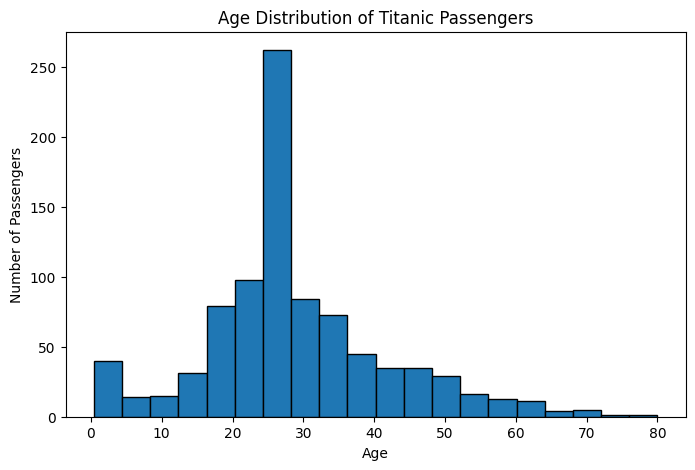

In [21]:
plt.figure(figsize=(8, 5))

plt.hist(df['age'], bins=20, edgecolor='black')

plt.title("Age Distribution of Titanic Passengers")
plt.xlabel("Age")
plt.ylabel("Number of Passengers")

plt.show()

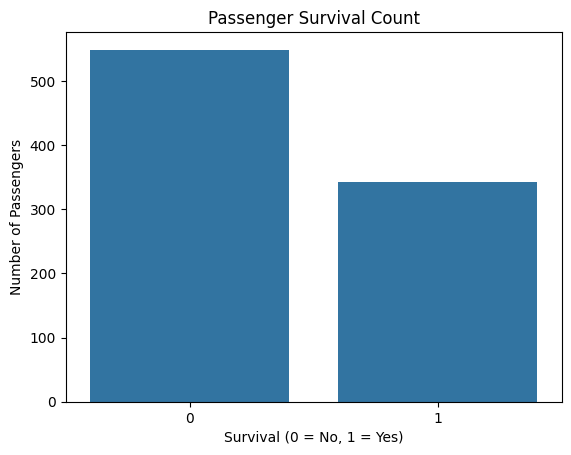

In [22]:
sns.countplot(data=df, x='survived')

plt.title("Passenger Survival Count")
plt.xlabel("Survival (0 = No, 1 = Yes)")
plt.ylabel("Number of Passengers")

plt.show()

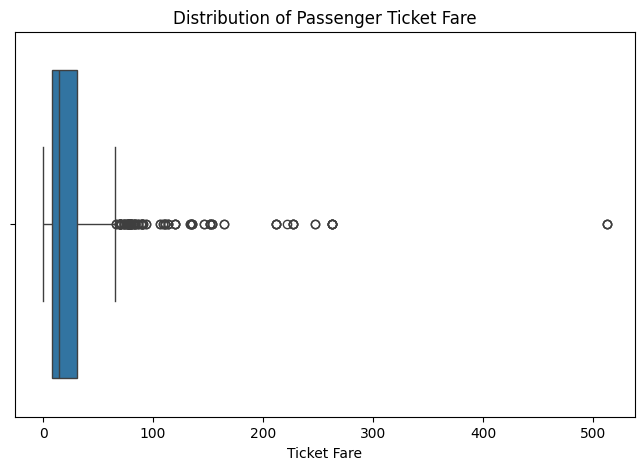

In [23]:
plt.figure(figsize=(8, 5))

sns.boxplot(x=df['fare'])

plt.title("Distribution of Passenger Ticket Fare")
plt.xlabel("Ticket Fare")

plt.show()

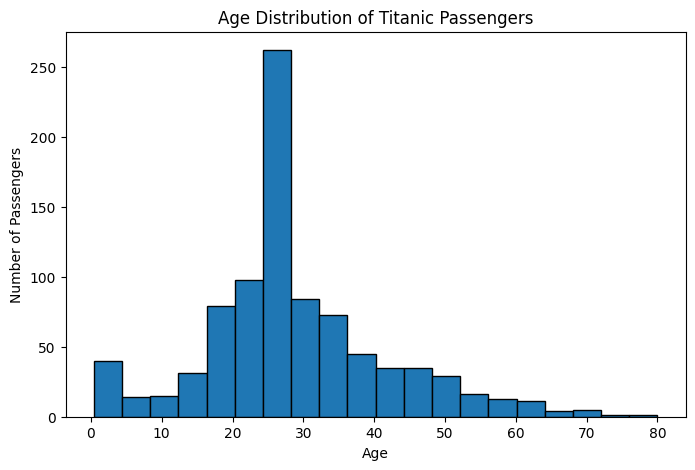

In [24]:
plt.figure(figsize=(8, 5))

plt.hist(df['age'], bins=20, edgecolor='black')

plt.title("Age Distribution of Titanic Passengers")
plt.xlabel("Age")
plt.ylabel("Number of Passengers")

plt.show()

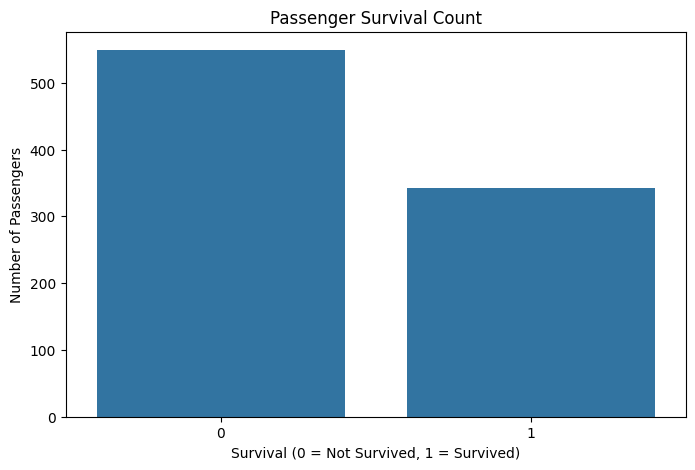

In [25]:
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x='survived')

plt.title("Passenger Survival Count")
plt.xlabel("Survival (0 = Not Survived, 1 = Survived)")
plt.ylabel("Number of Passengers")

plt.show()

In [26]:
# Remove alive because it duplicates survived

df = df.drop(columns=['alive'])

# Convert Boolean columns into integers

bool_columns = df.select_dtypes(include='bool').columns

df[bool_columns] = df[bool_columns].astype(int)

# Identify categorical columns

categorical_columns = df.select_dtypes(
    include=['object']
).columns

print("Categorical Columns:")
print(list(categorical_columns))

# Apply One-Hot Encoding

df = pd.get_dummies(
    df,
    columns=categorical_columns,
    dtype=int
)

print("\nEncoding Completed Successfully!")

# Display encoded dataset

df.head()

Categorical Columns:
['sex', 'embarked', 'class', 'who', 'embark_town']

Encoding Completed Successfully!


,survived,pclass,age,sibsp,parch,fare,adult_male,alone,sex_female,sex_male,...,embarked_S,class_First,class_Second,class_Third,who_child,who_man,who_woman,embark_town_Cherbourg,embark_town_Queenstown,embark_town_Southampton
0,0,3,22.0,1,0,7.2500,1,0,0,1,...,1,0,0,1,0,1,0,0,0,1
1,1,1,38.0,1,0,71.2833,0,0,1,0,...,0,1,0,0,0,0,1,1,0,0
2,1,3,26.0,0,0,7.9250,0,1,1,0,...,1,0,0,1,0,0,1,0,0,1
3,1,1,35.0,1,0,53.1000,0,0,1,0,...,1,1,0,0,0,0,1,0,0,1
4,0,3,35.0,0,0,8.0500,1,1,0,1,...,1,0,0,1,0,1,0,0,0,1


In [27]:
from sklearn.preprocessing import StandardScaler

print("StandardScaler imported successfully!")

StandardScaler imported successfully!


In [28]:
# Select numerical features

numerical_features = [
    'pclass',
    'age',
    'sibsp',
    'parch',
    'fare'
]

# Create scaler

scaler = StandardScaler()

# Apply scaling

df[numerical_features] = scaler.fit_transform(
    df[numerical_features]
)

print("Feature Scaling Completed Successfully!")

Feature Scaling Completed Successfully!


In [29]:
df[numerical_features].head()

,pclass,age,sibsp,parch,fare
0,0.827377,-0.565736,0.432793,-0.473674,-0.502445
1,-1.566107,0.663861,0.432793,-0.473674,0.786845
2,0.827377,-0.258337,-0.474545,-0.473674,-0.488854
3,-1.566107,0.433312,0.432793,-0.473674,0.420730
4,0.827377,0.433312,-0.474545,-0.473674,-0.486337


In [30]:
# Check final dataset

print("Final Dataset Shape:", df.shape)

print("Missing Values:", df.isnull().sum().sum())

# Save dataset

df.to_csv("Titanic_Prepared_Dataset.csv", index=False)

print("Dataset saved successfully!")

Final Dataset Shape: (891, 22)
Missing Values: 0
Dataset saved successfully!


In [31]:
from google.colab import files

files.download("Titanic_Prepared_Dataset.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [32]:
# Verify feature scaling

print("Mean of scaled features:")
print(df[numerical_features].mean())

print("\nStandard deviation:")
print(df[numerical_features].std())

Mean of scaled features:
pclass   -8.772133e-17
age       2.272780e-16
sibsp     4.386066e-17
parch     5.382900e-17
fare      3.987333e-18
dtype: float64

Standard deviation:
pclass    1.000562
age       1.000562
sibsp     1.000562
parch     1.000562
fare      1.000562
dtype: float64
